# 9.A.3. Глобальная модель (ETNA, M4 Hourly)

В 9.A.1 бустинг на одном коротком ряде едва обгонял линейную модель. Его настоящая сила —
**одна модель на много рядов**: деревья учат общие закономерности (суточный профиль, выходные)
сразу по всем рядам, и данных для обучения становится в сотни раз больше.

Данные — почасовая часть соревнования M4: 414 рядов, горизонт 48 часов, метрика sMAPE.

Вопрос ноутбука: **одна модель на ряд или одна на всех?**

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import time  # noqa: E402

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from etna.analysis import plot_forecast  # noqa: E402
from etna.datasets import TSDataset  # noqa: E402
from etna.metrics import SMAPE  # noqa: E402
from etna.models import (  # noqa: E402
    CatBoostMultiSegmentModel,
    CatBoostPerSegmentModel,
    LinearMultiSegmentModel,
    SeasonalMovingAverageModel,
)
from etna.pipeline import Pipeline  # noqa: E402
from etna.transforms import (  # noqa: E402
    DateFlagsTransform,
    LagTransform,
    LogTransform,
    SegmentEncoderTransform,
    StandardScalerTransform,
    TimeFlagsTransform,
)

H = 48

## 0. Данные

В M4 нет дат: каждая строка — ряд, столбцы `V2…V961` — номера шагов. Ряды бывают двух длин
(960 и 700 часов), короткие добиты `NaN` в хвосте. Тест — следующие 48 значений каждого ряда.

ETNA нужен общий календарь, поэтому выравниваем ряды **по правому краю**: конец train у всех
рядов — один и тот же час, тест идёт сразу после него. Дата старта условная.

In [2]:
train_wide = pd.read_csv(common.DATA / "Hourly-train.csv", index_col=0)
test_wide = pd.read_csv(common.DATA / "Hourly-test.csv", index_col=0)
print(f"train: {train_wide.shape}, test: {test_wide.shape}")
print("длины рядов:", train_wide.notna().sum(axis=1).value_counts().to_dict())

train: (414, 960), test: (414, 48)
длины рядов: {960: 245, 700: 169}


In [3]:
n_train = train_wide.shape[1]
timestamps = pd.date_range("2020-01-01", periods=n_train + H, freq="h")


def to_long(values: pd.DataFrame, stamps) -> pd.DataFrame:
    """Широкую таблицу (ряд × шаг) в длинную `timestamp, segment, target`, выровняв ряды вправо."""
    rows = []
    for segment, row in values.iterrows():
        v = row.dropna().to_numpy()
        rows.append(pd.DataFrame({"timestamp": stamps[-len(v):], "segment": segment, "target": v}))
    return pd.concat(rows, ignore_index=True)


long_train = to_long(train_wide, timestamps[:n_train])
long_test = to_long(test_wide, timestamps[n_train:])
ts_full = TSDataset(TSDataset.to_dataset(pd.concat([long_train, long_test])), freq="h")
train_ts, test_ts = ts_full.train_test_split(test_size=H)
print(f"сегментов: {len(train_ts.segments)}, train: {train_ts.timestamps[0]} … {train_ts.timestamps[-1]}")

сегментов: 414, train: 2020-01-01 00:00:00 … 2020-02-09 23:00:00


Ряды очень разного масштаба — от десятков до сотен тысяч. Для одной общей модели это главная
проблема: дерево легко научится «делить по уровню», а не по форме (проверим в разделе 3).

{'count': 414.0, 'mean': 6828.0, 'std': 38582.0, 'min': 14.0, '25%': 19.0, '50%': 83.0, '75%': 930.0, 'max': 524855.0}


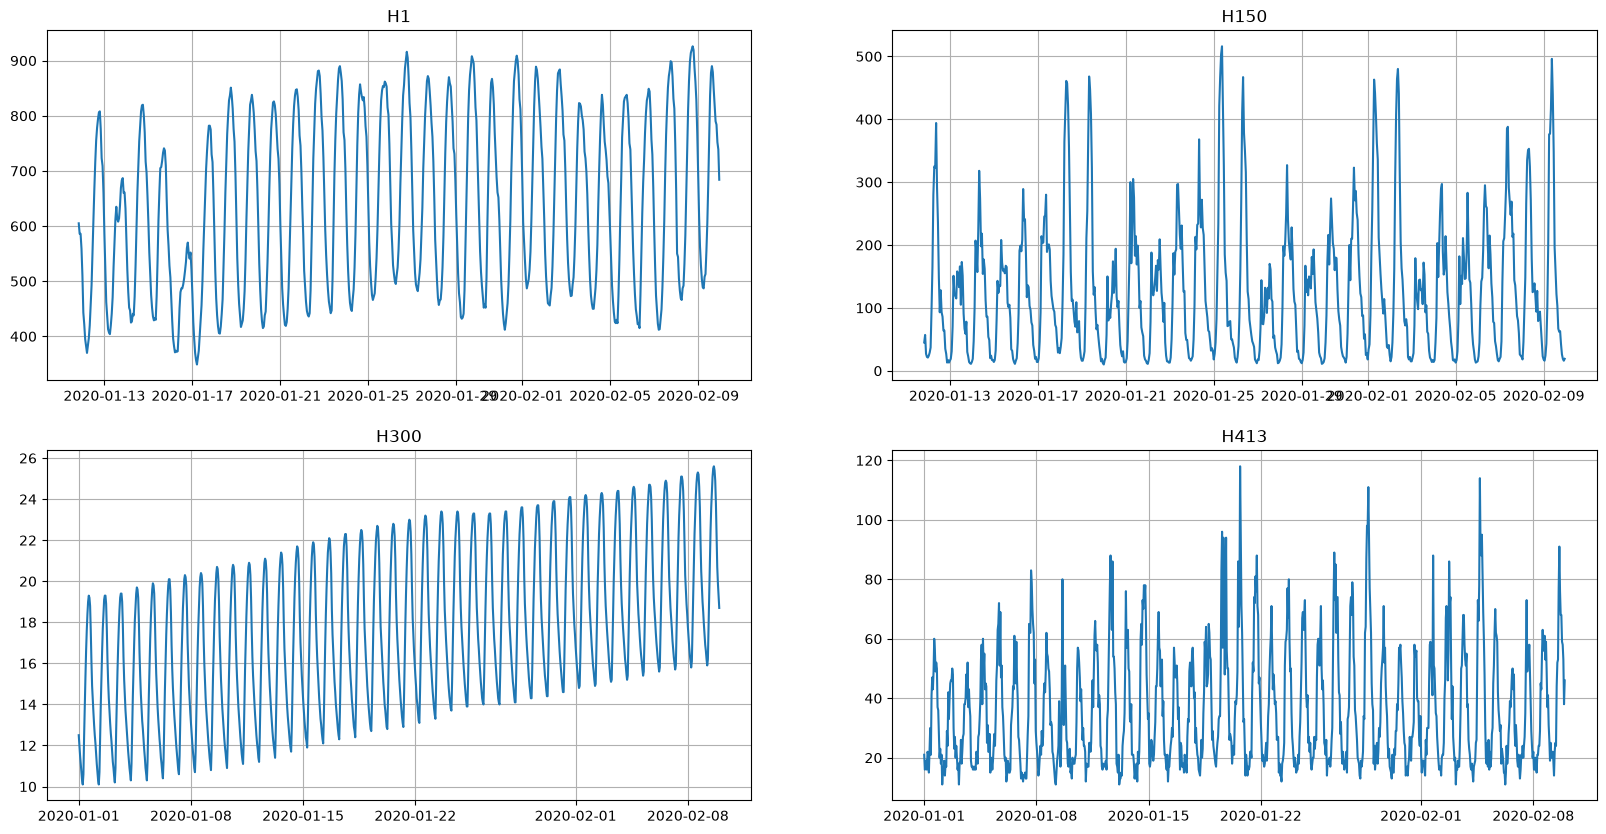

In [4]:
example = ["H1", "H150", "H300", "H413"]
scales = train_wide.mean(axis=1)
print(scales.describe().round(0).to_dict())
train_ts.plot(segments=example, n_segments=len(example))

## 1. Признаки и бейзлайны

Набор признаков одинаков для всех моделей:
- `LogTransform` на target — выравнивает масштаб и делает сезонность аддитивной;
- лаги 48…71 (последние сутки, доступные на горизонте 48), 168 и 336 (неделя и две недели назад);
- календарь: час, день недели, выходной.

In [5]:
def make_transforms(log=True, scale=False, segment_code=False):
    transforms = [LogTransform(in_column="target")] if log else []
    if scale:
        transforms.append(StandardScalerTransform(in_column="target", mode="per-segment"))
    transforms += [
        LagTransform(in_column="target", lags=list(range(H, H + 24)) + [168, 336], out_column="lag"),
        DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=True, out_column="date"),
        TimeFlagsTransform(minute_in_hour_number=False, hour_number=True, out_column="time"),
    ]
    if segment_code:
        transforms.append(SegmentEncoderTransform())
    return transforms


results = {}


def evaluate(name, model, transforms):
    """Обучить пайплайн на train, посчитать средний по рядам sMAPE на тесте и время."""
    start = time.perf_counter()
    pipeline = Pipeline(model=model, transforms=transforms, horizon=H)
    pipeline.fit(train_ts)
    forecast = pipeline.forecast()
    elapsed = time.perf_counter() - start
    per_segment = SMAPE()(y_true=test_ts, y_pred=forecast)
    results[name] = {"sMAPE": np.mean(list(per_segment.values())), "время, с": elapsed}
    print(f"{name}: sMAPE = {results[name]['sMAPE']:.2f}, {elapsed:.0f} с")
    return forecast

Бейзлайны: сезонный наивный (значение неделю назад) и одна линейная модель на все ряды.

In [6]:
naive_fc = evaluate("naive (неделю назад)", SeasonalMovingAverageModel(window=1, seasonality=168), [])
evaluate("Linear, глобальная", LinearMultiSegmentModel(), make_transforms());

naive (неделю назад): sMAPE = 12.70, 0 с
Linear, глобальная: sMAPE = 11.07, 7 с


Linear, глобальная: sMAPE = 11.07, 7 с


## 2. Per-segment vs глобальная

- `CatBoostPerSegmentModel` — отдельный бустинг на каждый из 414 рядов;
- `CatBoostMultiSegmentModel` — один бустинг, обученный на строках всех рядов сразу.

In [7]:
CATBOOST = dict(iterations=500, depth=4, random_seed=0, thread_count=4)
per_segment_fc = evaluate("CatBoost per-segment", CatBoostPerSegmentModel(**CATBOOST), make_transforms())

CatBoost per-segment: sMAPE = 10.31, 103 с


In [8]:
global_fc = evaluate("CatBoost глобальная", CatBoostMultiSegmentModel(**CATBOOST), make_transforms())

CatBoost глобальная: sMAPE = 10.43, 16 с


Глобальная модель того же качества и **в разы быстрее**: одна модель вместо 414.
Она к тому же видит в 414 раз больше примеров: суточный профиль, выученный на одних рядах,
помогает на других. Чем короче отдельные ряды, тем важнее это преимущество.

## 3. Что нужно глобальной модели

Все модели выше работали с логарифмом target. Проверим, что он даёт, и что ещё можно добавить:
- сырой target — без логарифма;
- сырой target + `StandardScalerTransform(mode="per-segment")` — нормировка каждого ряда
  по его среднему и стандартному отклонению;
- логарифм + нормировка;
- логарифм + `SegmentEncoderTransform` — номер ряда как категориальный признак.

In [9]:
evaluate("глобальная: без log", CatBoostMultiSegmentModel(**CATBOOST), make_transforms(log=False))
evaluate("глобальная: без log + scaler", CatBoostMultiSegmentModel(**CATBOOST), make_transforms(log=False, scale=True))
evaluate("глобальная: log + scaler", CatBoostMultiSegmentModel(**CATBOOST), make_transforms(scale=True))
evaluate("глобальная: log + segment", CatBoostMultiSegmentModel(**CATBOOST), make_transforms(segment_code=True));

глобальная: без log: sMAPE = 32.28, 14 с
глобальная: без log + scaler: sMAPE = 11.70, 15 с
глобальная: log + scaler: sMAPE = 10.42, 17 с
глобальная: log + segment: sMAPE = 10.32, 20 с


глобальная: без log + scaler: sMAPE = 11.70, 15 с


глобальная: log + scaler: sMAPE = 10.36, 16 с


глобальная: log + segment: sMAPE = 10.30, 20 с


- **Без снятия масштаба глобальная модель разваливается**: ошибка в разы выше наивной. Ряд
  со средним 500 000 и ряд со средним 20 для дерева — разные «объекты», и сплиты уходят на уровень.
- Нормировка по ряду почти спасает, но **логарифм лучше**: он не только выравнивает уровень, но и
  делает мультипликативную сезонность аддитивной, а лаги — относительными («на сколько процентов
  выше, чем неделю назад»).
- После логарифма ни нормировка, ни код ряда (`SegmentEncoderTransform`) качество заметно не
  меняют: разница в сотые доли sMAPE — на уровне разброса между запусками многопоточного
  CatBoost. Главное — снять масштаб, дальше общая закономерность важнее особенностей ряда.

## 4. Итоги

In [10]:
pd.DataFrame(results).T.round(2)

,sMAPE,"время, с"
naive (неделю назад),12.70,0.03
"Linear, глобальная",11.07,7.27
CatBoost per-segment,10.31,102.70
CatBoost глобальная,10.43,16.16
глобальная: без log,32.28,14.06
глобальная: без log + scaler,11.70,14.90
глобальная: log + scaler,10.42,16.67
глобальная: log + segment,10.32,19.56


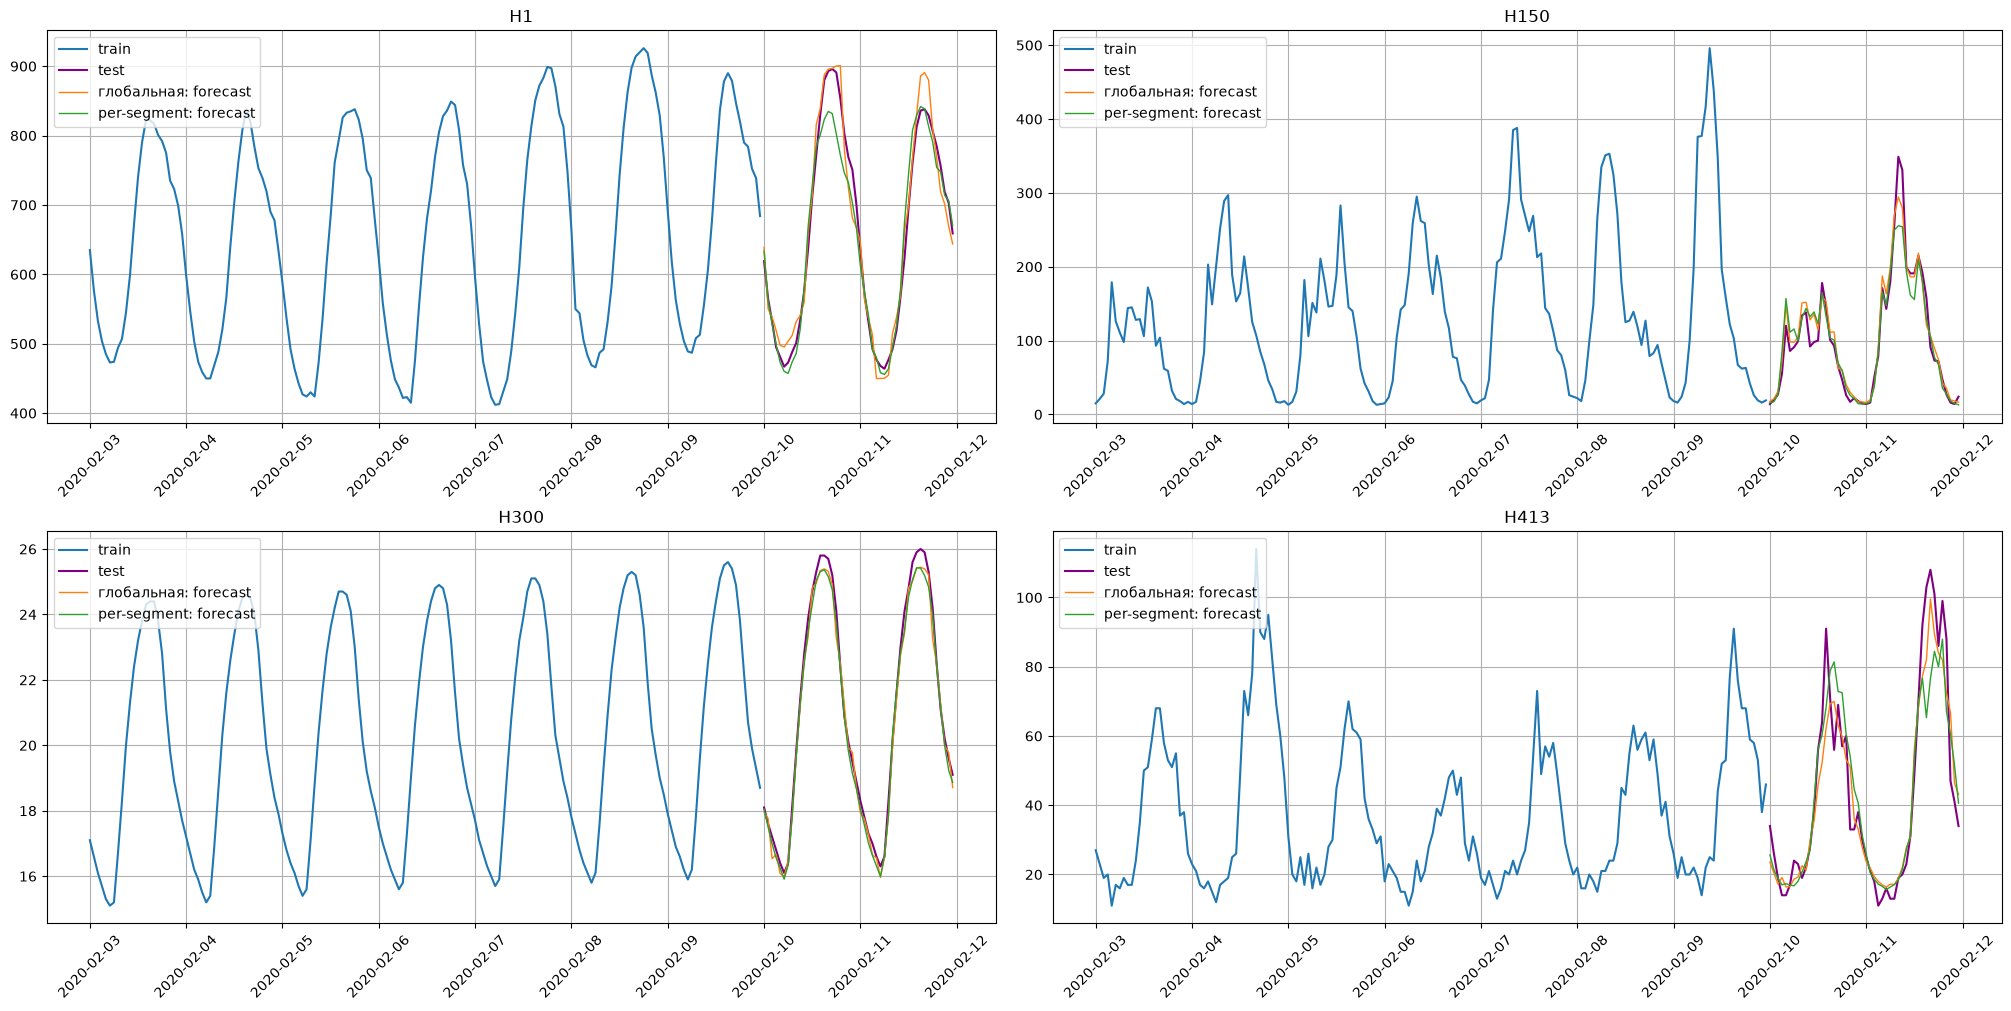

In [11]:
plot_forecast(
    forecast_ts={"глобальная": global_fc, "per-segment": per_segment_fc},
    test_ts=test_ts,
    train_ts=train_ts,
    segments=example,
    n_train_samples=168,
)

1. **Глобальная модель — главная сила бустинга во временных рядах**: то же или лучшее качество,
   в разы быстрее, одна модель в проде вместо сотен. Глобальные LightGBM-модели заняли верх
   рейтинга M5.
2. **Глобальной модели надо снять масштаб**: иначе деревья тратят сплиты на то, «какой это ряд
   по уровню», а не на форму. Для положительных рядов лучший способ — логарифм.
3. **Лаги ≥ H** позволяют одной модели прогнозировать весь горизонт сразу (как `Pipeline` в ETNA);
   другие способы использовать свежие значения — стратегии прогнозирования (блок 3).